# RwandaCropGuard – Kaggle GPU experiments

40 full experiments (10 x DQN, REINFORCE, A2C, PPO) using TorchRL.

Settings: GPU + Internet ON. 40000 steps per experiment (~650-700 episodes).

Repo: https://github.com/francis-collab/francis_mutabazi_rl_summative.git


## 1. Clone repository and install dependencies


In [2]:
import os
from pathlib import Path

os.chdir("/kaggle/working")

# Fresh clone
!rm -rf francis_mutabazi_rl_summative
!git clone https://github.com/francis-collab/francis_mutabazi_rl_summative.git

os.chdir("/kaggle/working/francis_mutabazi_rl_summative")
print("CWD:", os.getcwd())
print("Files:", sorted(os.listdir("."))[:20])

!pip -q install "torchrl>=0.7.0" "tensordict>=0.7.0" "gymnasium>=0.29.0" matplotlib pandas tqdm seaborn

import torch
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Cloning into 'francis_mutabazi_rl_summative'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 34 (delta 0), reused 34 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 260.48 KiB | 9.65 MiB/s, done.
CWD: /kaggle/working/francis_mutabazi_rl_summative
Files: ['.git', '.python-version', 'README.md', '__pycache__', 'assets', 'environment', 'evaluate.py', 'main.py', 'notebooks', 'pyproject.toml', 'run_experiments.py', 'tests', 'training', 'uv.lock']
Torch: 2.11.0+cu130
CUDA available: True


## 2. Hyperparameter grids (10 per algorithm)

Defined in source and used by run_experiments.py:

**DQN** (training/dqn_training.py):

| Exp | LR | Gamma | Batch | eps start | eps end | eps decay |
|-----|-----|-------|-------|-----------|---------|-----------|
| exp01 | 1e-3 | 0.99 | 64 | 1.0 | 0.05 | 12000 |
| exp02 | 3e-4 | 0.99 | 64 | 1.0 | 0.05 | 12000 |
| exp03 | 1e-4 | 0.99 | 64 | 1.0 | 0.05 | 12000 |
| exp04 | 1e-3 | 0.95 | 64 | 1.0 | 0.05 | 12000 |
| exp05 | 1e-3 | 0.99 | 128 | 1.0 | 0.05 | 12000 |
| exp06 | 1e-3 | 0.99 | 32 | 1.0 | 0.05 | 12000 |
| exp07 | 1e-3 | 0.99 | 64 | 1.0 | 0.01 | 12000 |
| exp08 | 1e-3 | 0.99 | 64 | 1.0 | 0.05 | 6000 |
| exp09 | 1e-3 | 0.99 | 64 | 1.0 | 0.05 | 20000 |
| exp10 | 3e-4 | 0.99 | 128 | 1.0 | 0.05 | 12000 |

**REINFORCE / A2C / PPO** (training/pg_training.py):

| Exp | LR | Gamma | Entropy | Rollout |
|-----|-----|-------|---------|---------|
| *_exp01 | 3e-4 | 0.99 | 0.01 | 256 |
| *_exp02 | 1e-4 | 0.99 | 0.01 | 256 |
| *_exp03 | 1e-3 | 0.99 | 0.01 | 256 |
| *_exp04 | 3e-4 | 0.95 | 0.01 | 256 |
| *_exp05 | 3e-4 | 0.99 | 0.001 | 256 |
| *_exp06 | 3e-4 | 0.99 | 0.05 | 256 |
| *_exp07 | 3e-4 | 0.99 | 0.01 | 128 |
| *_exp08 | 3e-4 | 0.99 | 0.01 | 512 |
| *_exp09 | 5e-4 | 0.99 | 0.01 | 256 |
| *_exp10 | 3e-4 | 0.995 | 0.01 | 256 |

Each run uses 40000 environment steps.


In [3]:
from training.dqn_training import dqn_hyperparameter_grid
from training.pg_training import pg_hyperparameter_grid

print("=== DQN (10) ===")
for c in dqn_hyperparameter_grid("cpu", 40_000):
    print(c.exp_name, "lr", c.lr, "gamma", c.gamma, "batch", c.batch_size,
          "eps", c.eps_start, "->", c.eps_end, "decay", c.eps_decay_steps)

for algo in ("reinforce", "a2c", "ppo"):
    print("\n===", algo.upper(), "(10) ===")
    for c in pg_hyperparameter_grid(algo, "cpu", 40_000):
        print(c.exp_name, "lr", c.lr, "gamma", c.gamma,
              "entropy", c.entropy_coef, "rollout", c.rollout_steps)


/usr/local/lib/python3.13/dist-packages/torchrl/_utils.py:132: DeprecationWarning: TorchRL support for torch<2.13 (found torch 2.11.0+cu130) is deprecated and will be removed in v0.17. torch 2.11 and 2.12 remain supported until then for stacks that pin them, such as Isaac Lab 3.0. Upgrade to torch>=2.13 to silence this warning.
  warnings.warn(


=== DQN (10) ===
exp01 lr 0.001 gamma 0.99 batch 64 eps 1.0 -> 0.05 decay 12000
exp02 lr 0.0003 gamma 0.99 batch 64 eps 1.0 -> 0.05 decay 12000
exp03 lr 0.0001 gamma 0.99 batch 64 eps 1.0 -> 0.05 decay 12000
exp04 lr 0.001 gamma 0.95 batch 64 eps 1.0 -> 0.05 decay 12000
exp05 lr 0.001 gamma 0.99 batch 128 eps 1.0 -> 0.05 decay 12000
exp06 lr 0.001 gamma 0.99 batch 32 eps 1.0 -> 0.05 decay 12000
exp07 lr 0.001 gamma 0.99 batch 64 eps 1.0 -> 0.01 decay 12000
exp08 lr 0.001 gamma 0.99 batch 64 eps 1.0 -> 0.05 decay 6000
exp09 lr 0.001 gamma 0.99 batch 64 eps 1.0 -> 0.05 decay 20000
exp10 lr 0.0003 gamma 0.99 batch 128 eps 1.0 -> 0.05 decay 12000

=== REINFORCE (10) ===
reinforce_exp01 lr 0.0003 gamma 0.99 entropy 0.01 rollout 256
reinforce_exp02 lr 0.0001 gamma 0.99 entropy 0.01 rollout 256
reinforce_exp03 lr 0.001 gamma 0.99 entropy 0.01 rollout 256
reinforce_exp04 lr 0.0003 gamma 0.95 entropy 0.01 rollout 256
reinforce_exp05 lr 0.0003 gamma 0.99 entropy 0.001 rollout 256
reinforce_exp06

## 3. Environment demo


In [4]:
!python main.py --mode demo


RwandaCropGuard demo – random policy
Observation shape: (18,)
Day 0/60 | Plot 0 | Chem=3 Org=8 Lab=12
Weather=0.36  YieldRisk=0.00
Plot | Disease | Moisture | Inspected
<< 0  |  0.19   |   0.34   | N
   1  |  0.11   |   0.69   | N
   2  |  0.21   |   0.60   | N
   3  |  0.17   |   0.61   | N
t=00 action=ALERT_COMMUNITY  reward=   1.25 total=    1.25
t=01 action=INSPECT          reward=   0.30 total=    1.55
t=02 action=IRRIGATE         reward=   0.80 total=    2.35
t=03 action=IRRIGATE         reward=   0.80 total=    3.15
t=04 action=APPLY_CHEMICAL   reward=   2.00 total=    5.15
t=05 action=ALERT_COMMUNITY  reward=   1.27 total=    6.42
t=06 action=INSPECT          reward=   0.30 total=    6.72
t=07 action=HARVEST          reward=   8.04 total=   14.76
Episode ended: {'current_plot': 0, 'disease': array([0.09224927, 0.20657887, 0.32582177, 0.30486576]), 'moisture': array([0.58422231, 0.46504009, 0.36879099, 0.38431319]), 'chemical': 2, 'organic': 8, 'labour': 5, 'day': 7, 'yield_risk

## 4. Run all 40 experiments


In [5]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
!python run_experiments.py --device {device} --total-steps 40000


Using device: cuda
/usr/local/lib/python3.13/dist-packages/torchrl/_utils.py:132: DeprecationWarning: TorchRL support for torch<2.13 (found torch 2.11.0+cu130) is deprecated and will be removed in v0.17. torch 2.11 and 2.12 remain supported until then for stacks that pin them, such as Isaac Lab 3.0. Upgrade to torch>=2.13 to silence this warning.
  warnings.warn(

DQN – 10 experiments

>>> exp01 lr=0.001 gamma=0.99 batch=64
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
DQN exp01:   0%|                                      | 0/40000 [00:00<?

## 5. Results summary tables


In [6]:
import json
from pathlib import Path
import pandas as pd
summary_path = Path("logs/full_experiment_summary.json")
if summary_path.is_file():
    summary = json.loads(summary_path.read_text())
    for algo, rows in summary.items():
        print("\n===", algo.upper(), "===")
        print(pd.DataFrame(rows).to_string(index=False))
else:
    print("Summary not found")



=== DQN ===
  exp     lr  gamma  batch_size  mean_last20  greedy_mean  num_episodes
exp01 0.0010   0.99          64    52.254340    54.788976          1385
exp02 0.0003   0.99          64    50.199730    57.607691          1397
exp03 0.0001   0.99          64    40.864943    45.010237          1457
exp04 0.0010   0.95          64    37.951373    48.175214          1396
exp05 0.0010   0.99         128    51.401061    59.334252          1442
exp06 0.0010   0.99          32    50.791792    59.267503          1413
exp07 0.0010   0.99          64    57.100383    56.569438          1317
exp08 0.0010   0.99          64    51.148340    59.007690          1127
exp09 0.0010   0.99          64    47.635582    59.246488          1765
exp10 0.0003   0.99         128    52.568899    57.214756          1393

=== REINFORCE ===
            exp     lr  gamma  entropy_coef  mean_last20  greedy_mean  num_episodes
reinforce_exp01 0.0003  0.990         0.010    13.094467     0.391883          5056
reinforc

## 6. Display training plots


Found 45 plots
models/dqn/best_model/training_plot.png


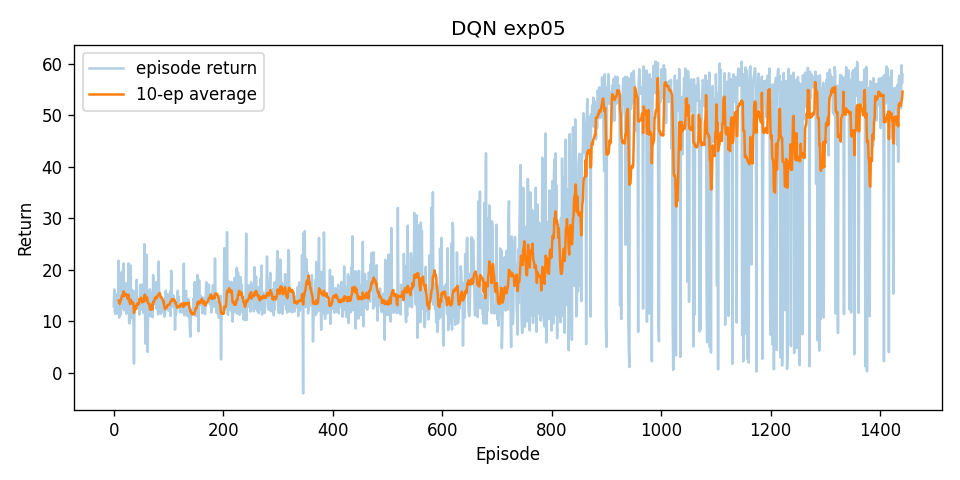

models/dqn/exp01/training_plot.png


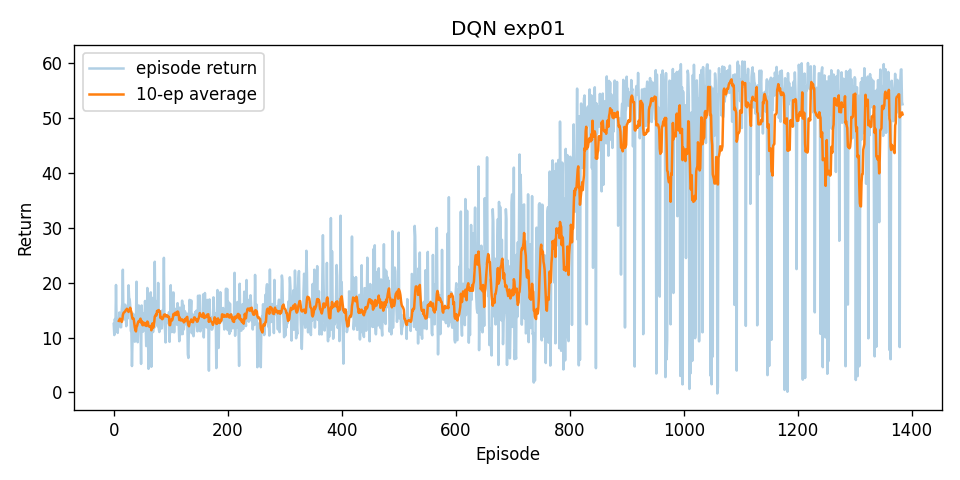

models/dqn/exp02/training_plot.png


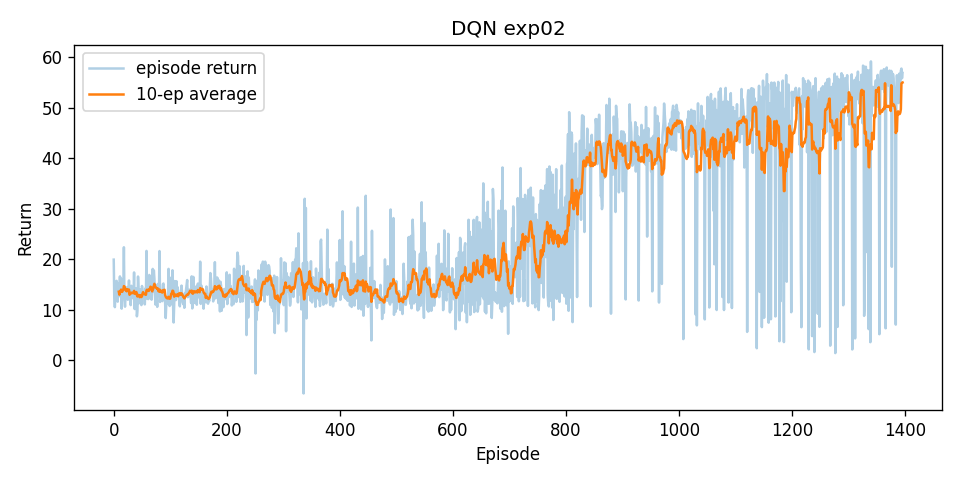

models/dqn/exp03/training_plot.png


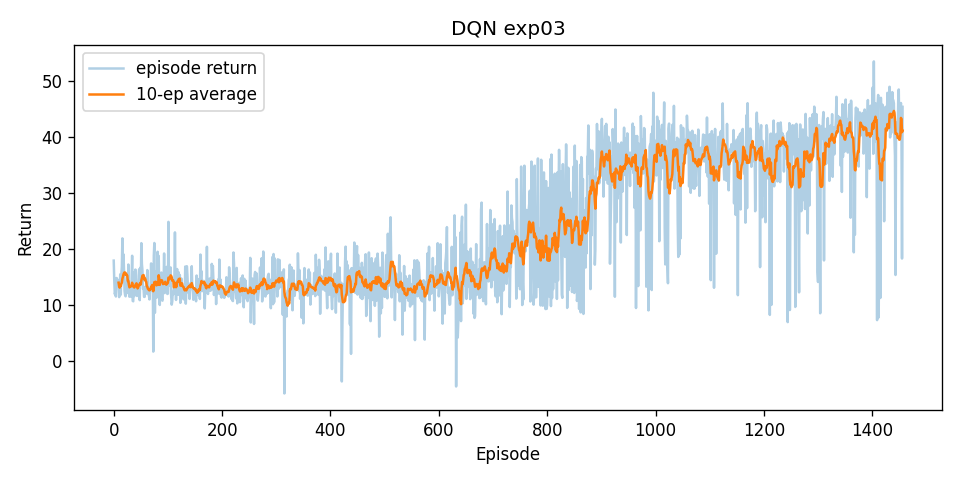

models/dqn/exp04/training_plot.png


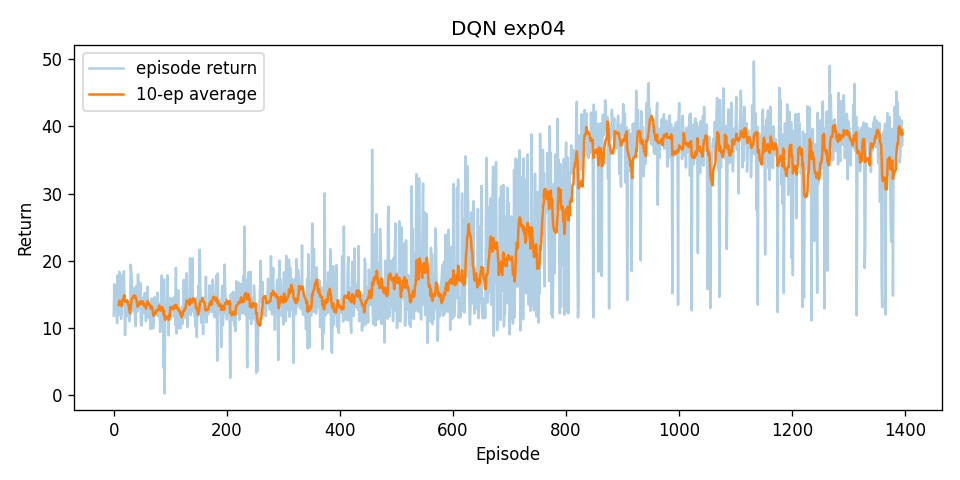

models/dqn/exp05/training_plot.png


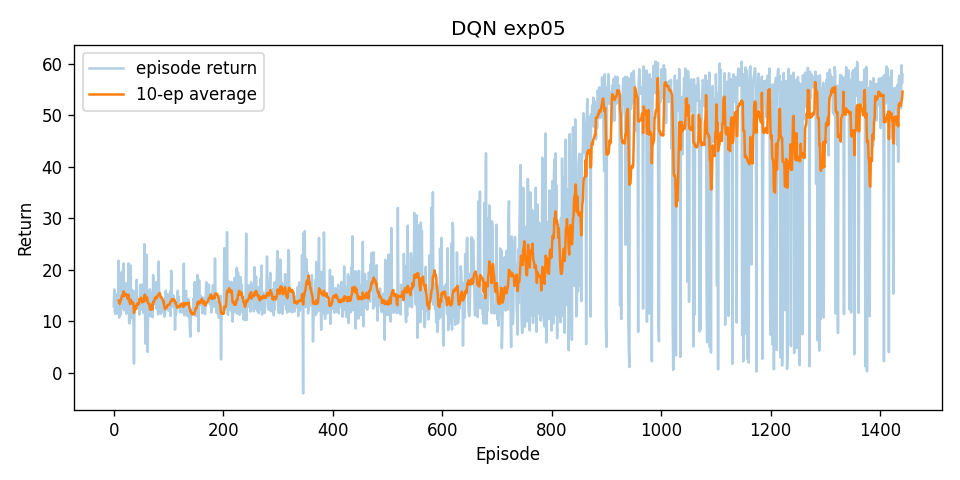

models/dqn/exp06/training_plot.png


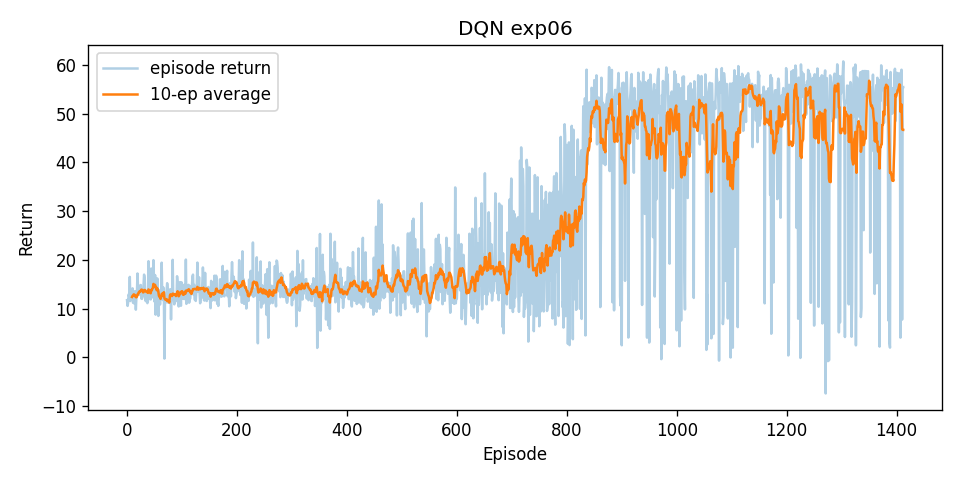

models/dqn/exp07/training_plot.png


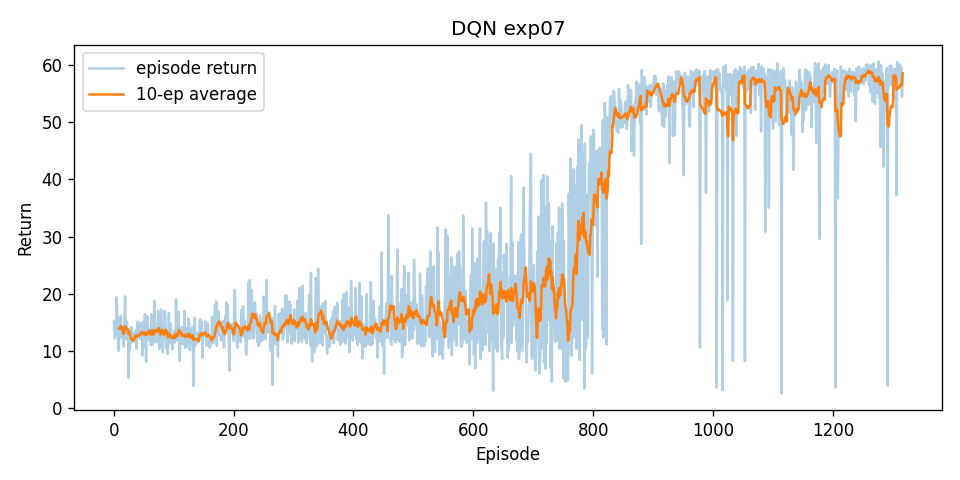

models/dqn/exp08/training_plot.png


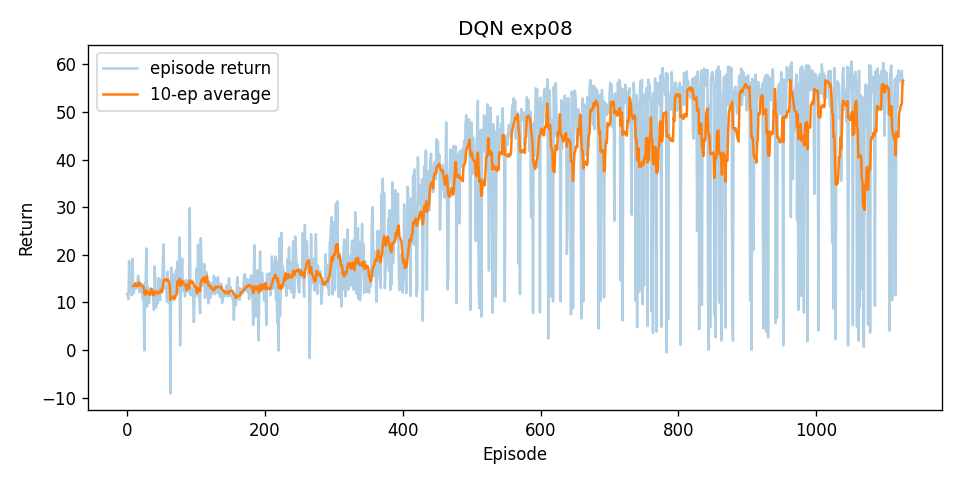

models/dqn/exp09/training_plot.png


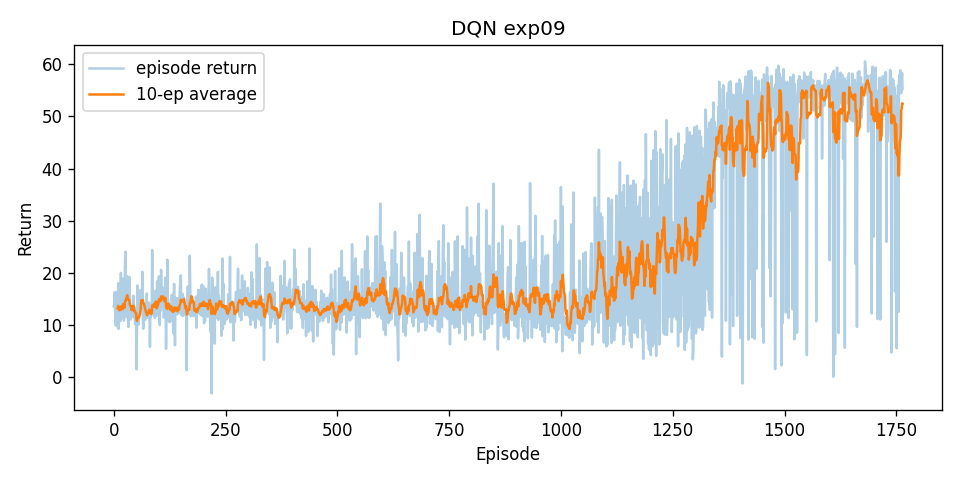

models/dqn/exp10/training_plot.png


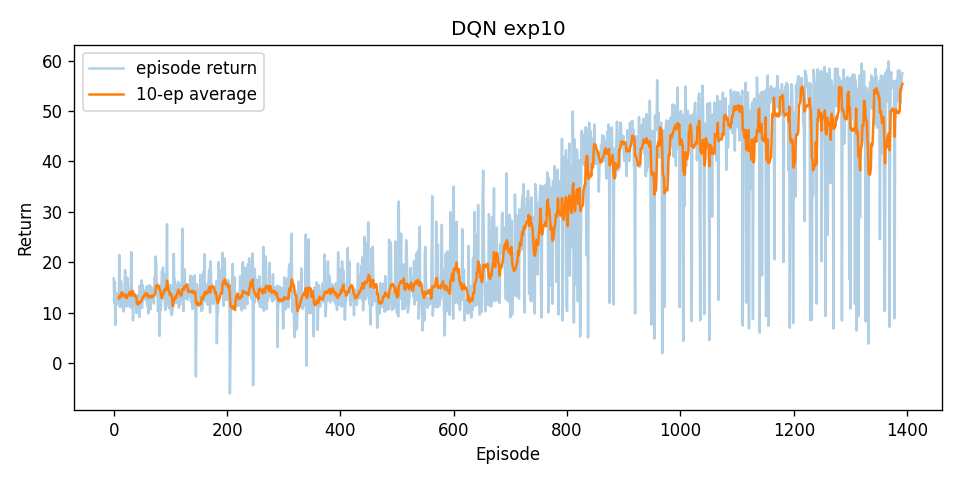

models/pg/a2c_best/training_plot.png


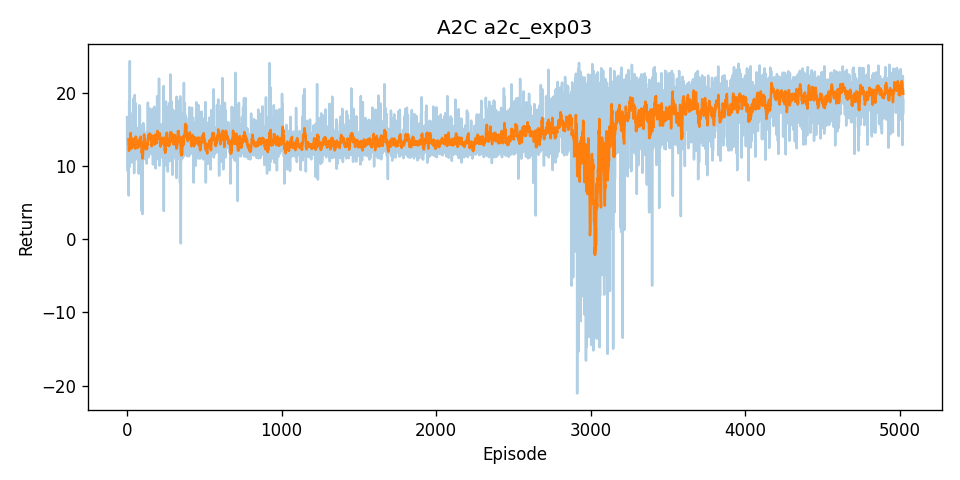

models/pg/a2c_exp01/training_plot.png


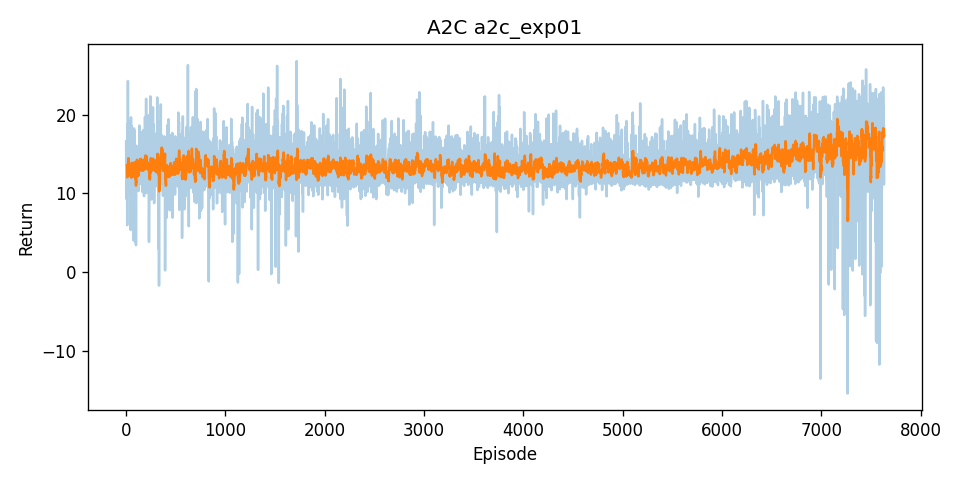

models/pg/a2c_exp02/training_plot.png


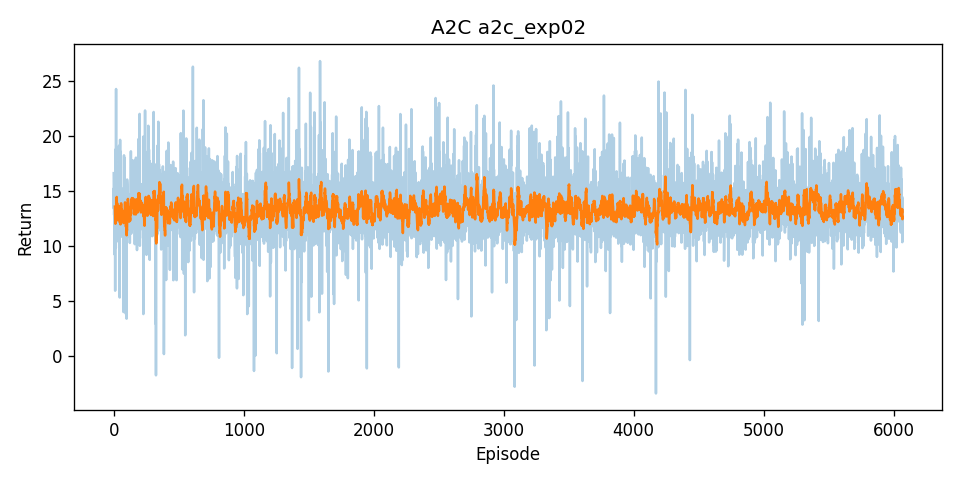

models/pg/a2c_exp03/training_plot.png


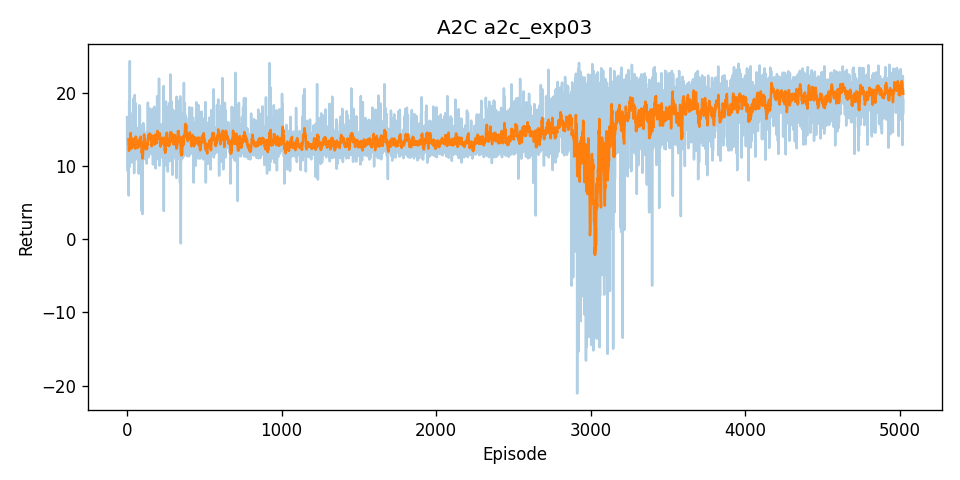

models/pg/a2c_exp04/training_plot.png


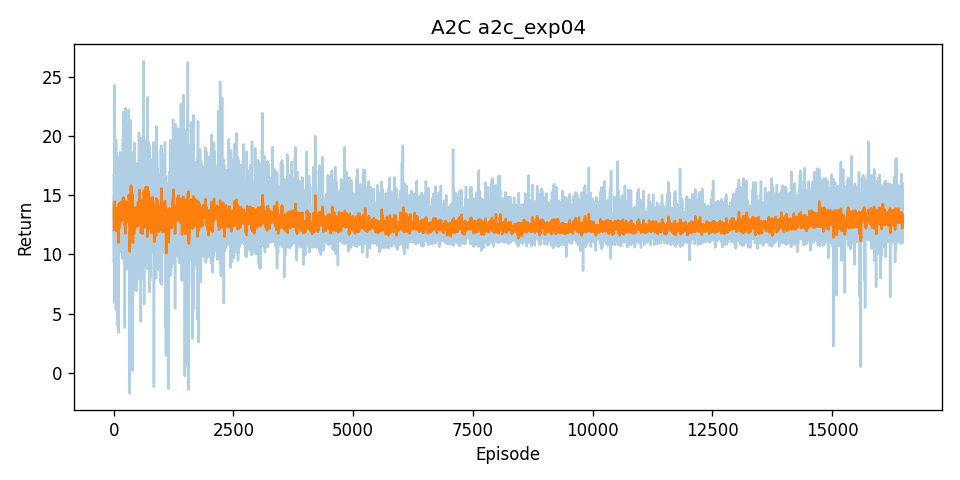

models/pg/a2c_exp05/training_plot.png


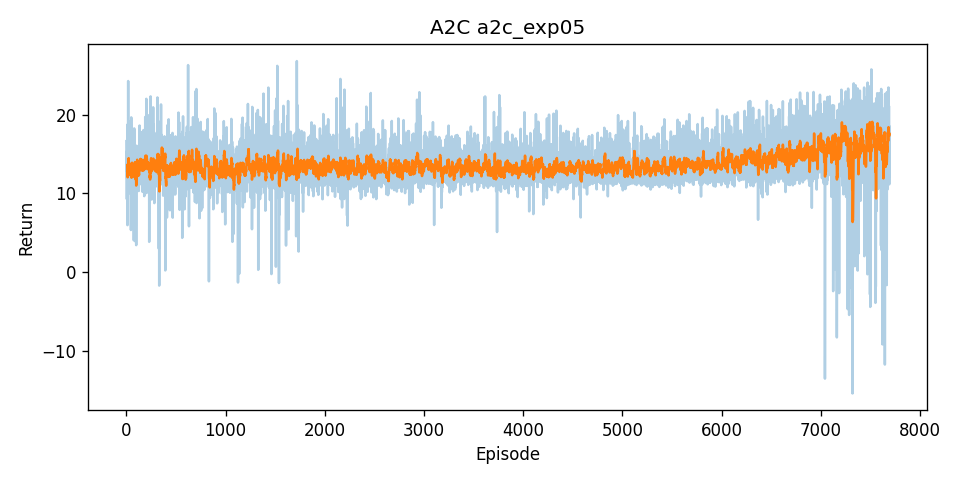

models/pg/a2c_exp06/training_plot.png


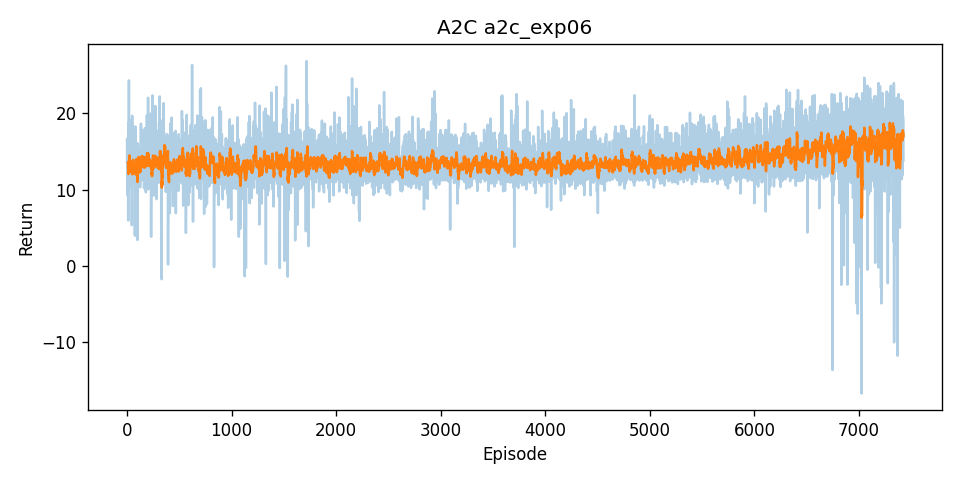

models/pg/a2c_exp07/training_plot.png


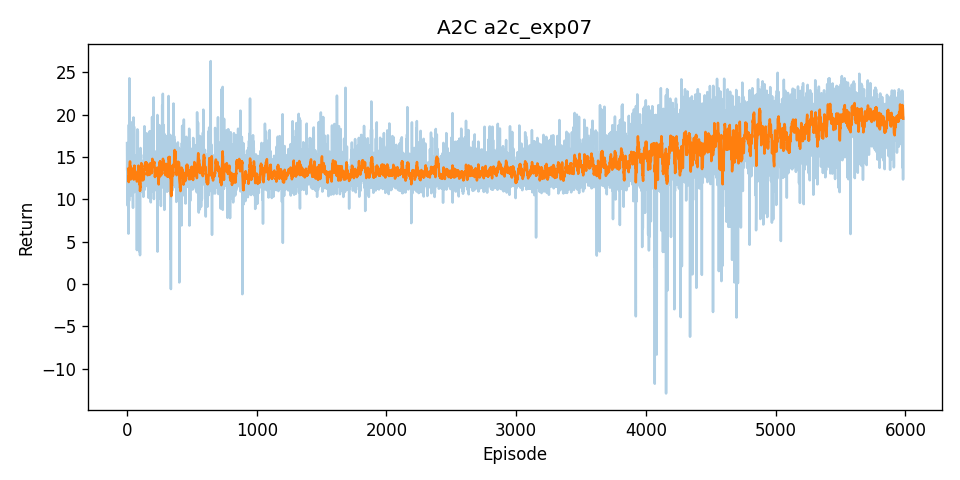

models/pg/a2c_exp08/training_plot.png


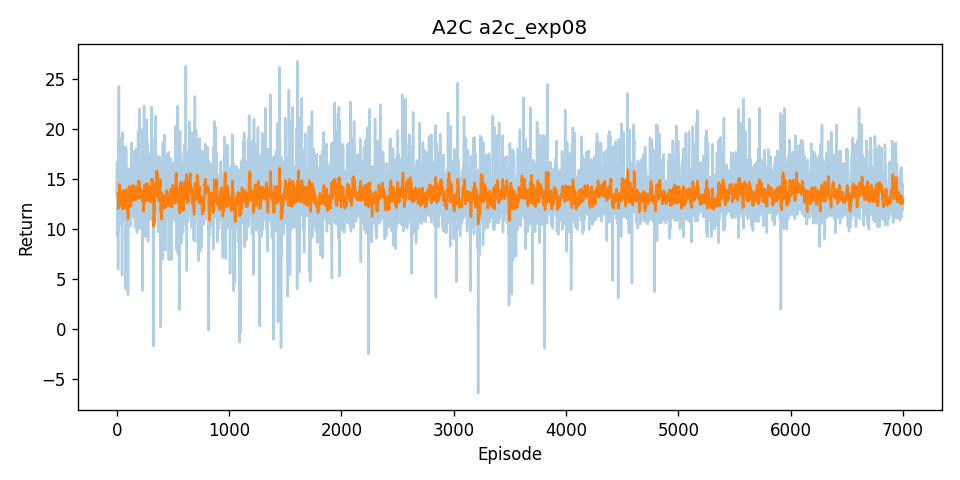

models/pg/a2c_exp09/training_plot.png


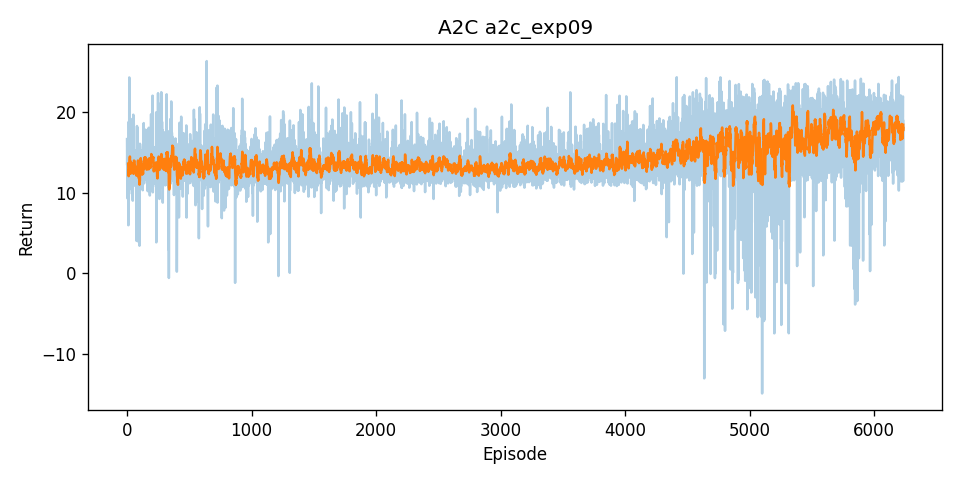

models/pg/a2c_exp10/training_plot.png


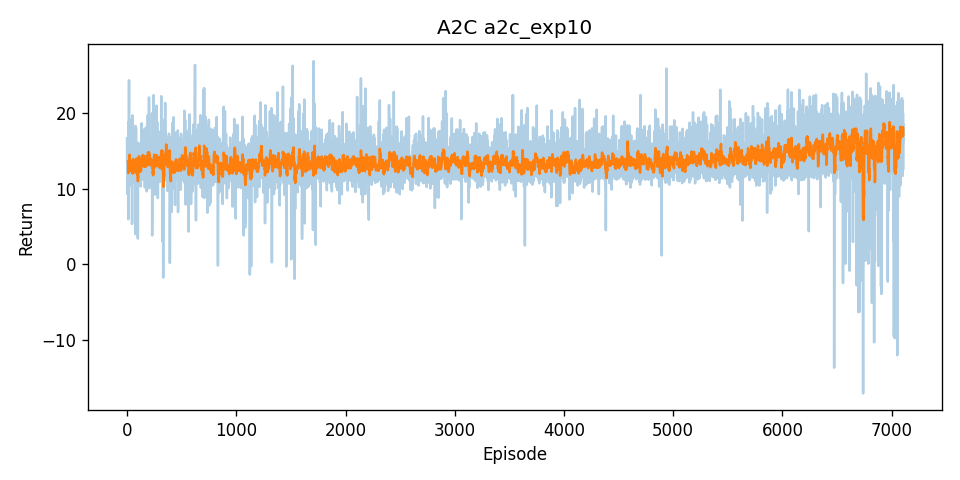

models/pg/best_model/training_plot.png


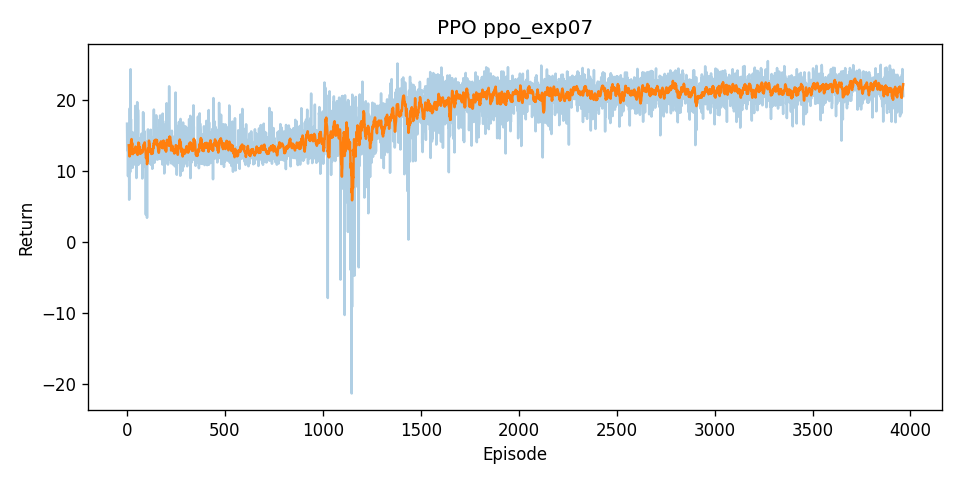

models/pg/ppo_best/training_plot.png


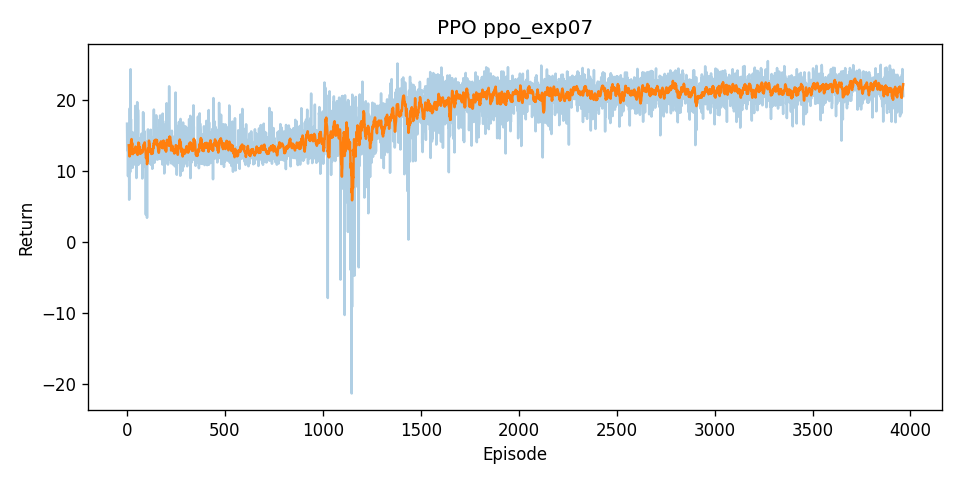

models/pg/ppo_exp01/training_plot.png


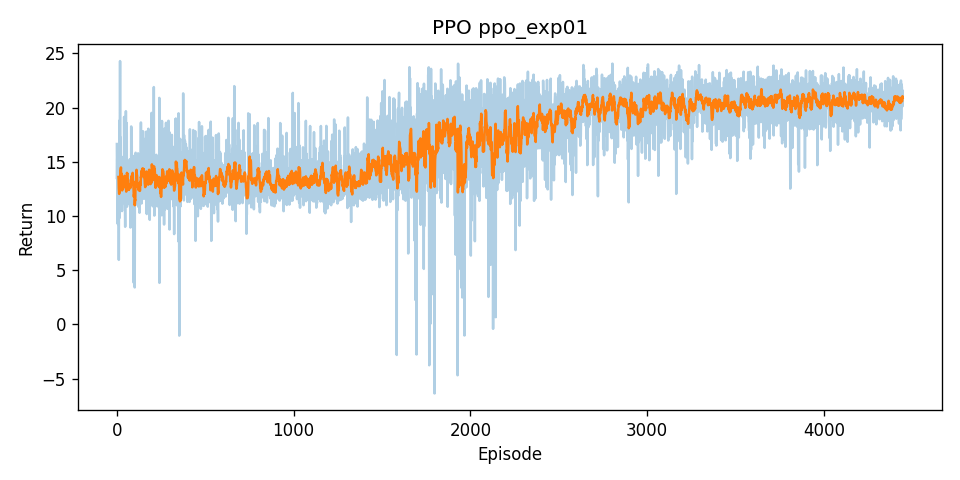

models/pg/ppo_exp02/training_plot.png


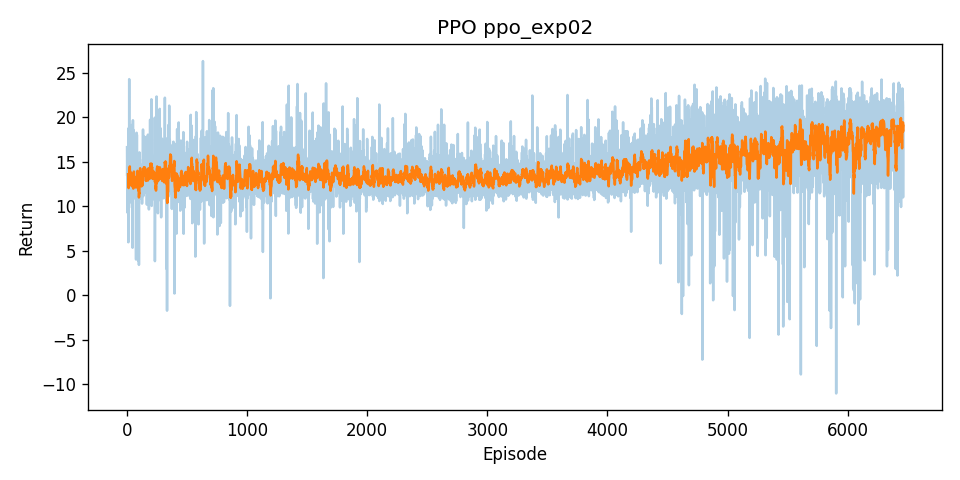

models/pg/ppo_exp03/training_plot.png


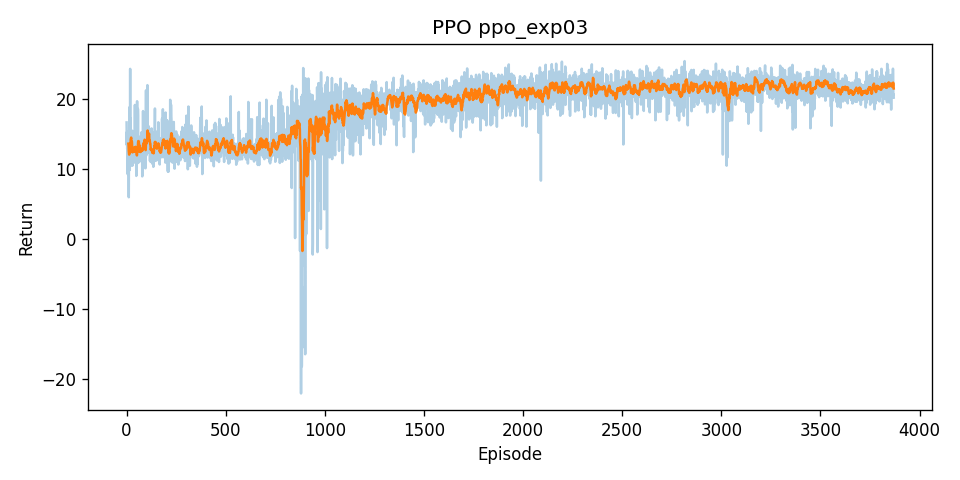

models/pg/ppo_exp04/training_plot.png


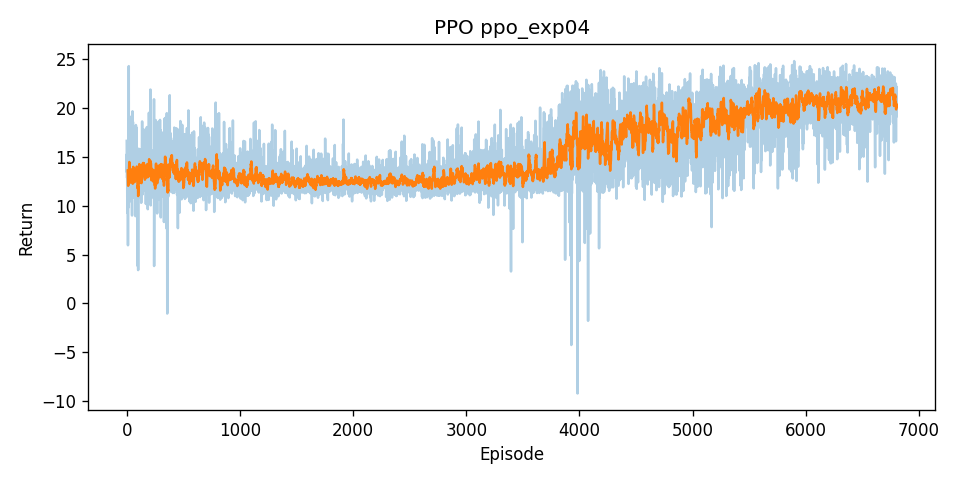

models/pg/ppo_exp05/training_plot.png


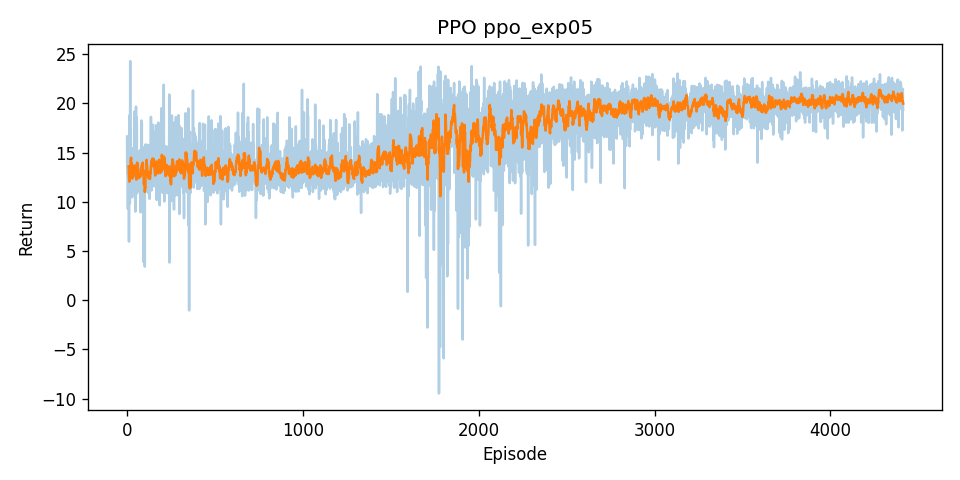

models/pg/ppo_exp06/training_plot.png


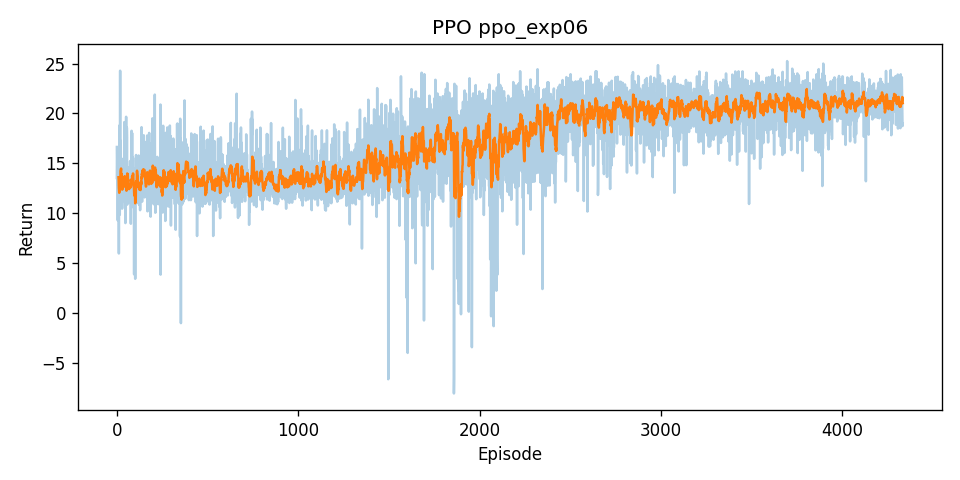

models/pg/ppo_exp07/training_plot.png


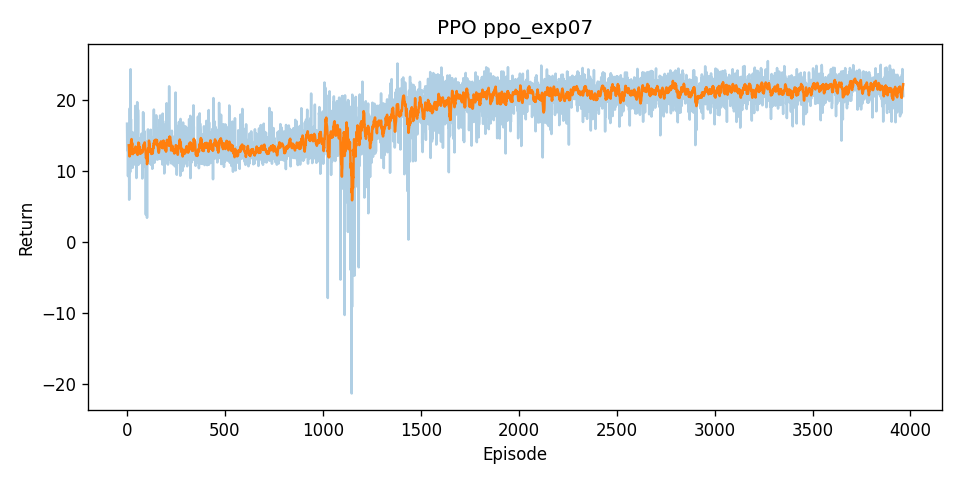

models/pg/ppo_exp08/training_plot.png


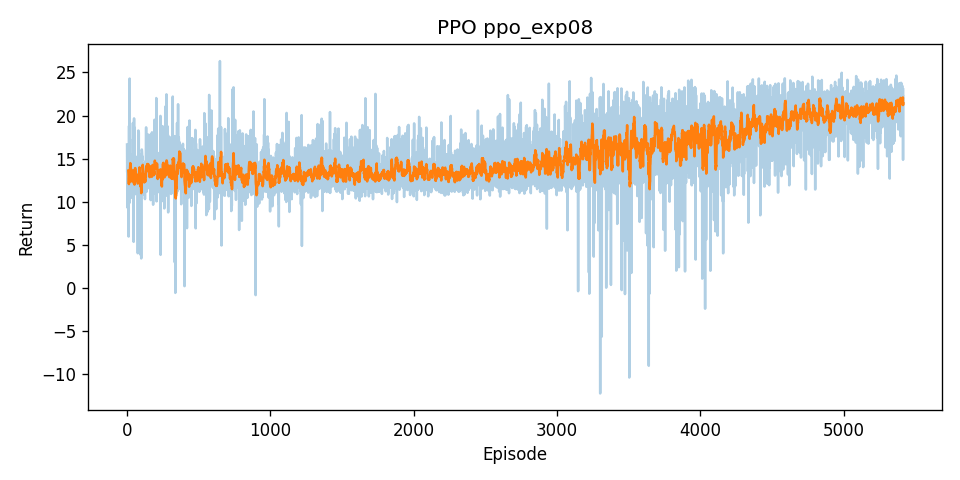

models/pg/ppo_exp09/training_plot.png


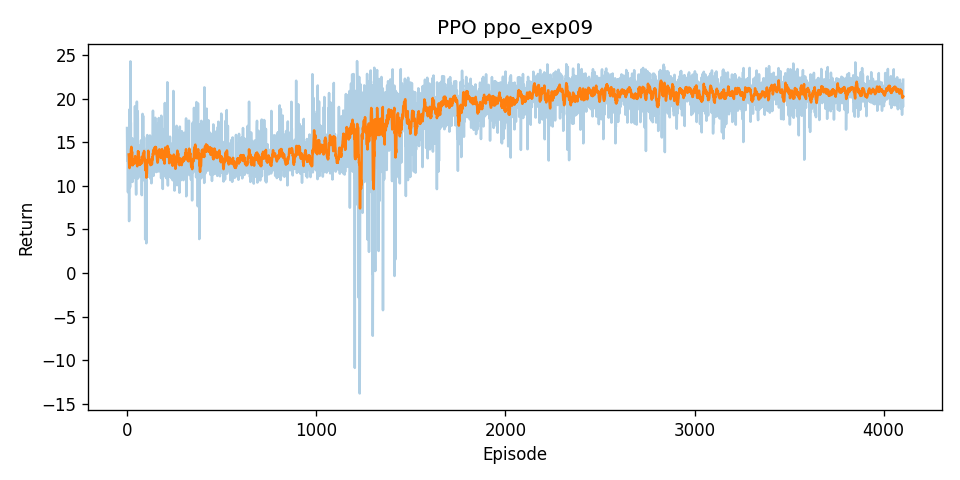

models/pg/ppo_exp10/training_plot.png


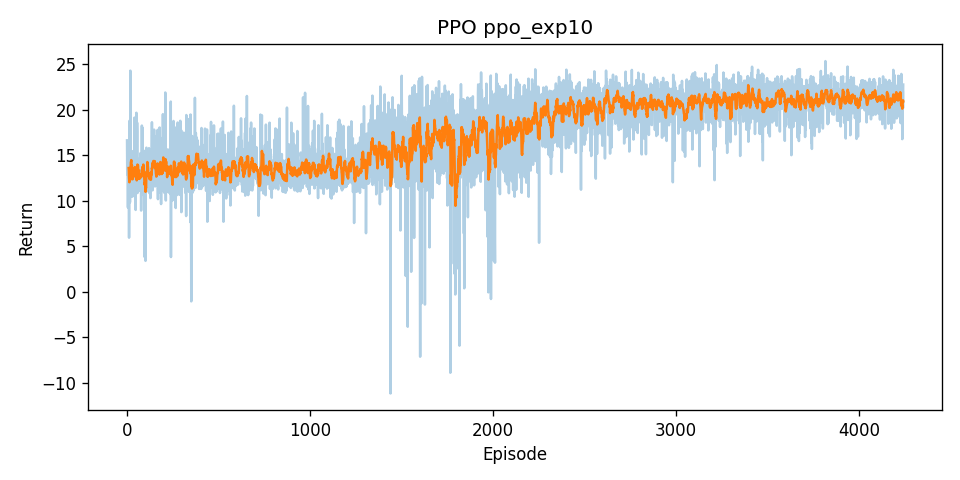

models/pg/reinforce_best/training_plot.png


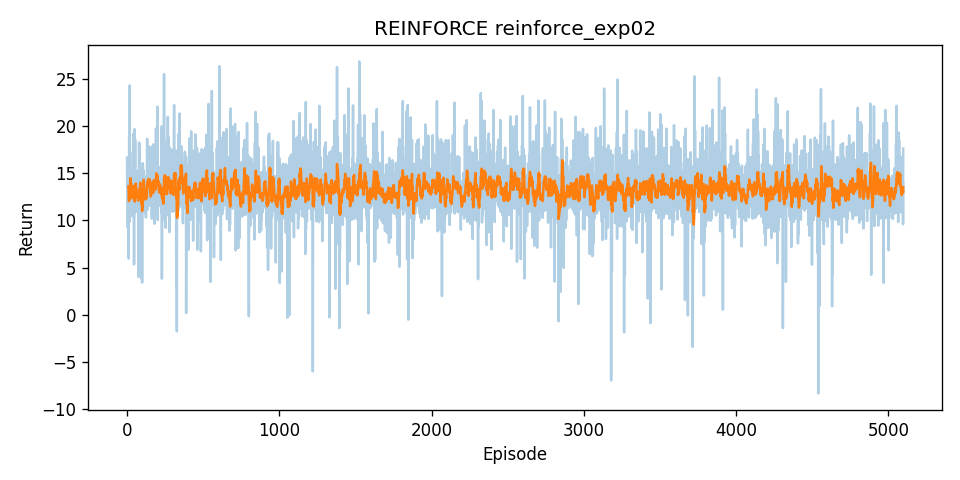

models/pg/reinforce_exp01/training_plot.png


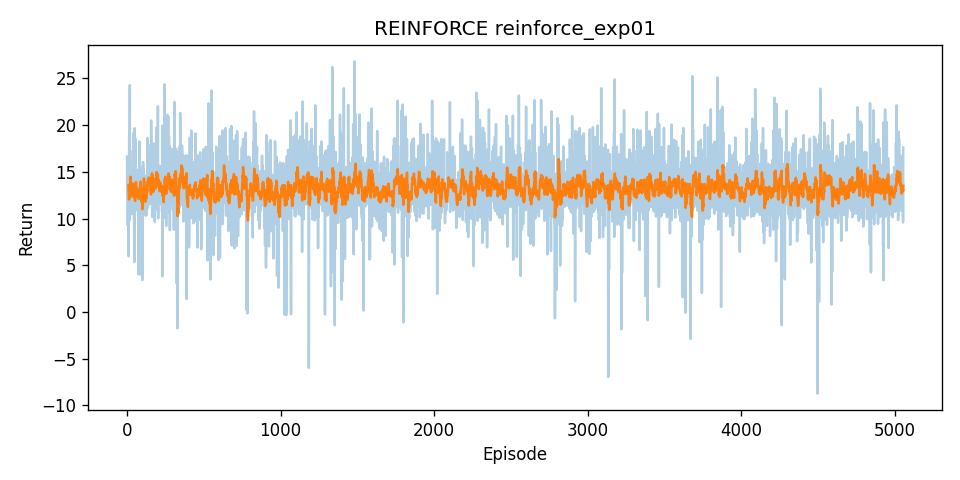

models/pg/reinforce_exp02/training_plot.png


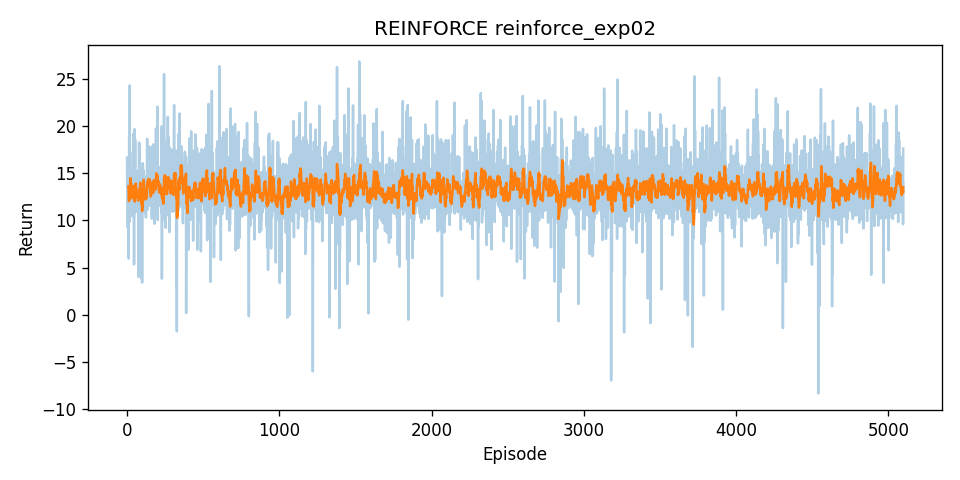

models/pg/reinforce_exp03/training_plot.png


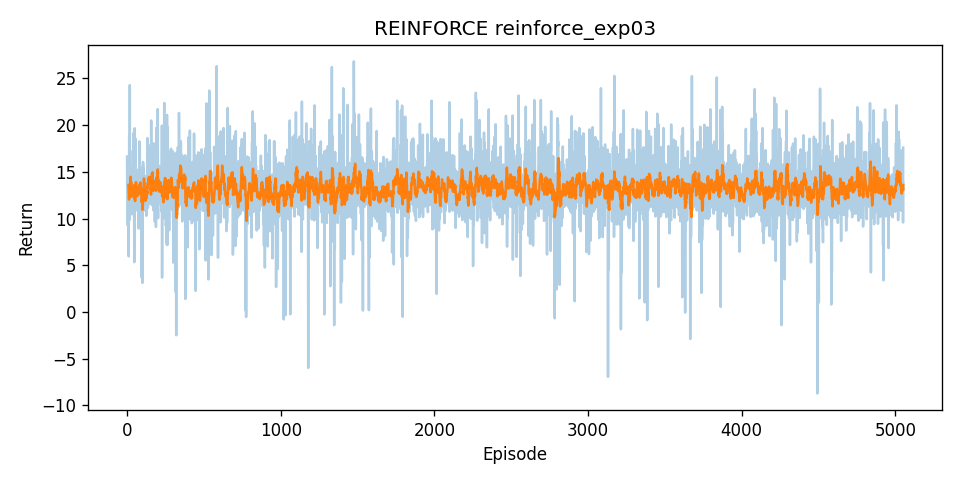

models/pg/reinforce_exp04/training_plot.png


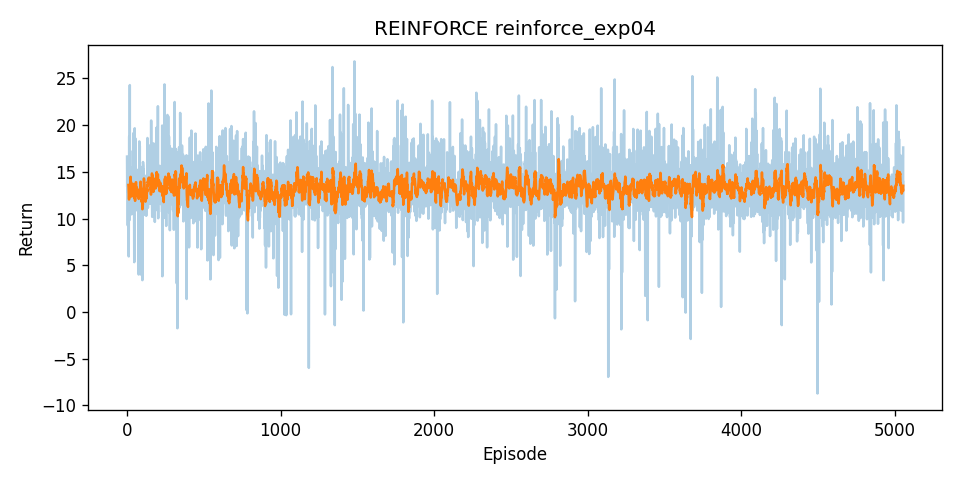

models/pg/reinforce_exp05/training_plot.png


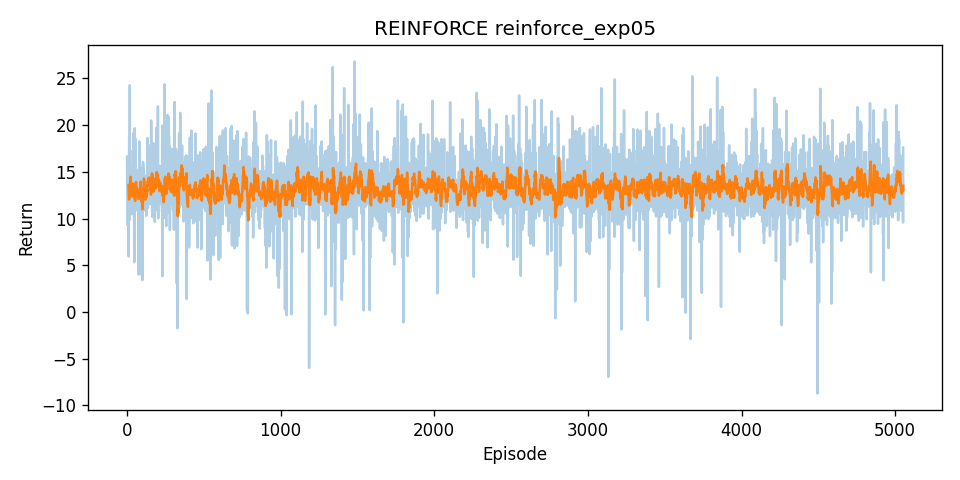

models/pg/reinforce_exp06/training_plot.png


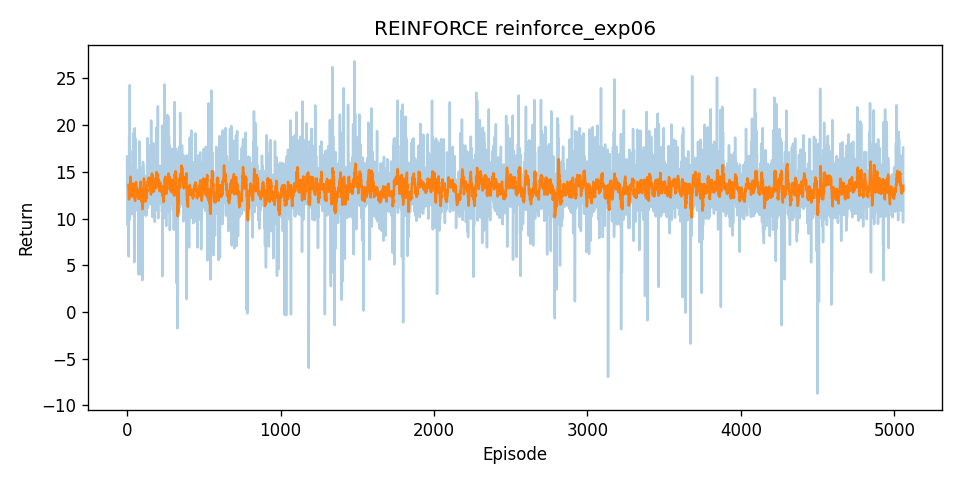

models/pg/reinforce_exp07/training_plot.png


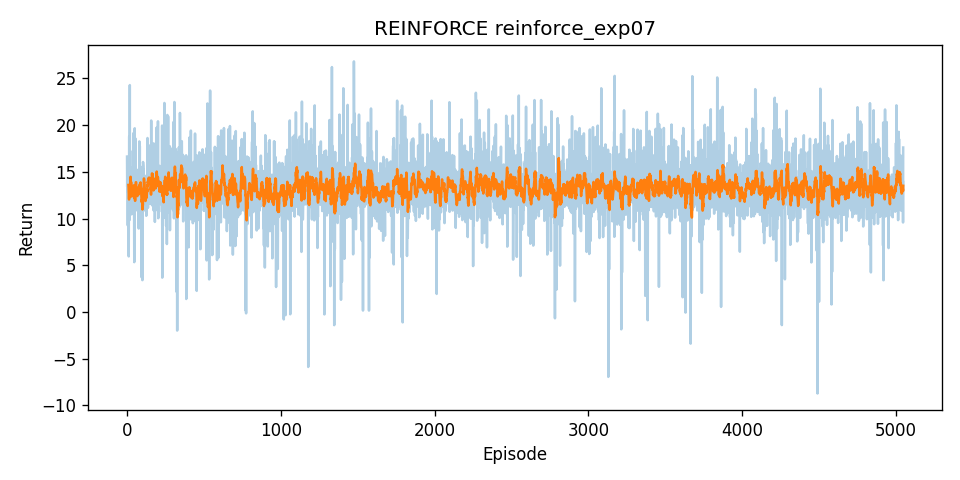

models/pg/reinforce_exp08/training_plot.png


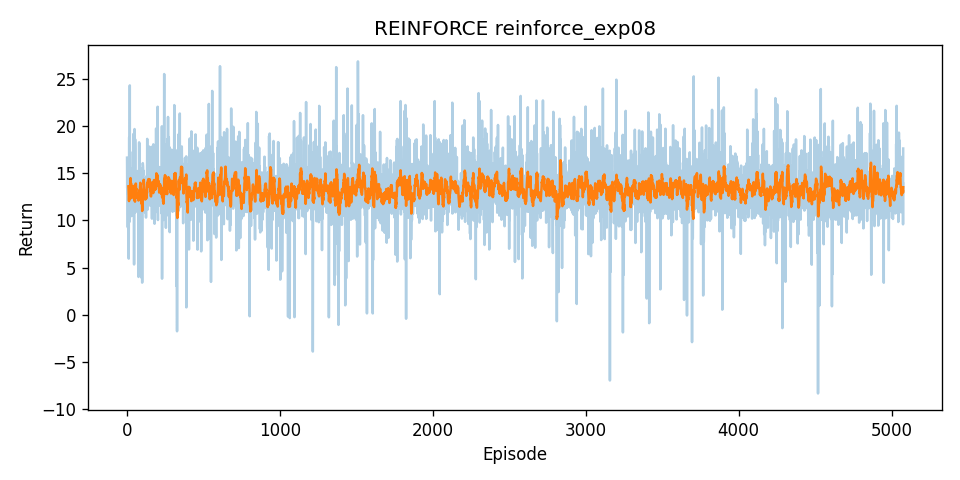

models/pg/reinforce_exp09/training_plot.png


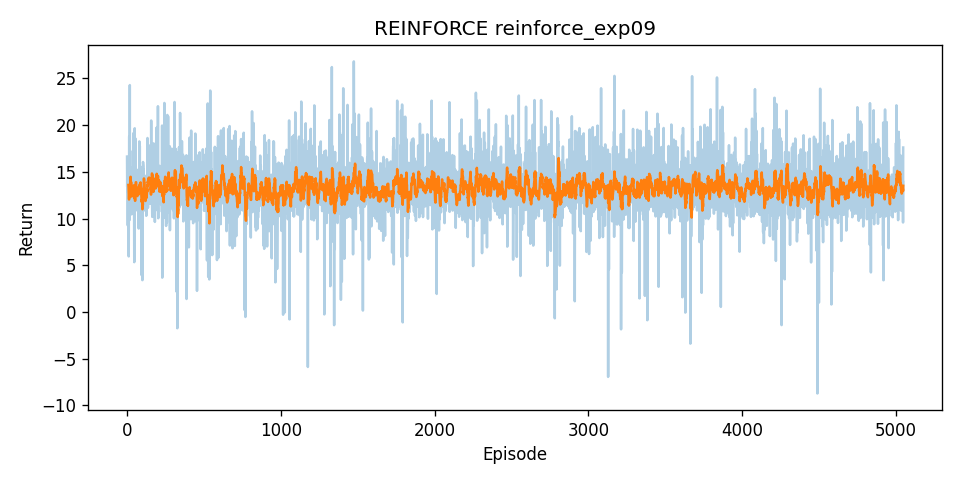

models/pg/reinforce_exp10/training_plot.png


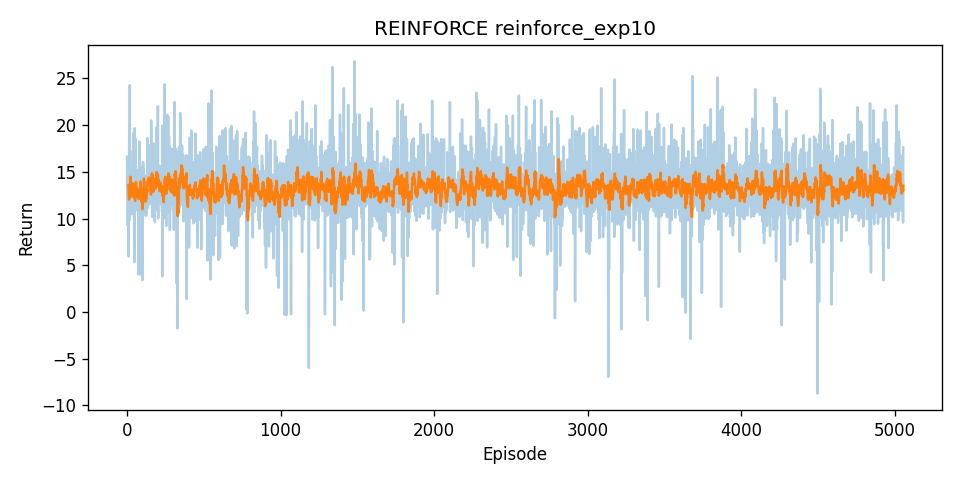

In [7]:
from IPython.display import Image, display
from pathlib import Path
plots = sorted(Path("models").rglob("training_plot.png"))
print("Found", len(plots), "plots")
for p in plots:
    print(p)
    display(Image(str(p)))


## 7. Zip artefacts for download


In [8]:
!zip -r /kaggle/working/rwanda_cropguard_results.zip models logs assets
!ls -lh /kaggle/working/rwanda_cropguard_results.zip
print("Download from Output panel")


  adding: models/ (stored 0%)
  adding: models/dqn/ (stored 0%)
  adding: models/dqn/exp05/ (stored 0%)
  adding: models/dqn/exp05/training_plot.png (deflated 3%)
  adding: models/dqn/exp05/dqn_model.pth (deflated 9%)
  adding: models/dqn/exp05/greedy_eval.json (deflated 43%)
  adding: models/dqn/exp05/results.json (deflated 58%)
  adding: models/dqn/exp02/ (stored 0%)
  adding: models/dqn/exp02/training_plot.png (deflated 4%)
  adding: models/dqn/exp02/dqn_model.pth (deflated 9%)
  adding: models/dqn/exp02/greedy_eval.json (deflated 44%)
  adding: models/dqn/exp02/results.json (deflated 58%)
  adding: models/dqn/exp06/ (stored 0%)
  adding: models/dqn/exp06/training_plot.png (deflated 4%)
  adding: models/dqn/exp06/dqn_model.pth (deflated 9%)
  adding: models/dqn/exp06/greedy_eval.json (deflated 44%)
  adding: models/dqn/exp06/results.json (deflated 58%)
  adding: models/dqn/exp08/ (stored 0%)
  adding: models/dqn/exp08/training_plot.png (deflated 3%)
  adding: models/dqn/exp08/dqn_mo